# Energy Prediction — Advanced Machine Learning

<small>Professional model-development notebook designed to export a reusable prediction model and feature schema for the Streamlit application.</small>

## Objective
Predict annual household energy consumption (`energy_tj`) from **country, end-use category, fuel, year, and lag-based historical signals**.

This is a supervised regression workflow with chronological validation and an exported model bundle. For a valid interactive prediction, the app must supply historical values for the same country/end-use/fuel series (or use the fallback feature values provided in the UI).

## 1. Environment & imports

In [25]:
# If needed, run:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

from pathlib import Path
import warnings, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

PROJECT_DIR = Path.cwd()

DATA_CANDIDATES = [
    PROJECT_DIR / "data" / "raw" / "european_household_energy.csv",
    PROJECT_DIR.parent / "data" / "raw" / "european_household_energy.csv",
    PROJECT_DIR / "european_household_energy.csv",
    PROJECT_DIR / "european_household_energy(1).csv",
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    if DATA_PATH is None:
        for search_dir in (PROJECT_DIR, PROJECT_DIR.parent):
            matches = list(search_dir.rglob("european_household_energy.csv"))
            if matches:
                DATA_PATH = sorted(matches, key=lambda p: len(p.parts))[0]
                break

    if DATA_PATH is None:
        raise FileNotFoundError(
            "Could not find 'european_household_energy.csv'. "
            "Place it in 'data/raw' or in the notebook project directory."
        )

ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)
print("Data:", DATA_PATH.resolve())

Data: C:\Users\LOQ\Downloads\archive (13)\european_household_energy.csv


## 2. Load and validate data

In [26]:
df = pd.read_csv(DATA_PATH)
required_cols = ["country", "is_country_group", "end_use_code", "fuel_code", "year", "energy_tj"]
missing = set(required_cols) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["energy_tj"] = pd.to_numeric(df["energy_tj"], errors="coerce")
df = df.dropna(subset=["country", "end_use_code", "fuel_code", "year", "energy_tj"])
df["year"] = df["year"].astype(int)

# Exclude aggregate country groups from the model training rows.
df = df[~df["is_country_group"].astype(bool)].copy()
display(df.head())
print("Shape:", df.shape)

,country_code,country_iso2,country,is_country_group,end_use_code,end_use,fuel_code,fuel,period,date,year,energy_tj,flag,flag_meaning
0,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2010,2010-01-01,2010,"10,790.820",NaN,NaN
1,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2011,2011-01-01,2011,"10,571.882",NaN,NaN
2,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2012,2012-01-01,2012,"11,036.876",NaN,NaN
3,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2013,2013-01-01,2013,"14,641.092",NaN,NaN
4,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2014,2014-01-01,2014,"12,600.004",NaN,NaN


Shape: (33356, 14)


## 3. Feature engineering — time-series signals per series

In [9]:
# Each distinct country/end-use/fuel combination is a series.
SERIES_KEYS = ["country", "end_use_code", "fuel_code"]
df = df.sort_values(SERIES_KEYS + ["year"]).reset_index(drop=True)

# Within each series, build past-only features. Rows with missing lag history
# are retained and handled by the imputer, which helps short series.
g = df.groupby(SERIES_KEYS, sort=False)["energy_tj"]
df["lag_1"] = g.shift(1)
df["lag_2"] = g.shift(2)
df["lag_3"] = g.shift(3)
df["rolling_mean_3"] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
df["rolling_std_3"] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=2).std())
df["year"] = df["year"].astype(int)
df["year_index"] = df["year"] - df["year"].min()
df["year_sq"] = df["year_index"] ** 2

# Note: only historical lags are used; current target is never included as a feature.
display(df[["country","end_use_code","fuel_code","year","energy_tj","lag_1","lag_2","rolling_mean_3"]].head(12))

,country,end_use_code,fuel_code,year,energy_tj,lag_1,lag_2,rolling_mean_3
0,Albania,FC_OTH_HH_E,E7000,2010,"10,790.820",NaN,NaN,NaN
1,Albania,FC_OTH_HH_E,E7000,2011,"10,571.882","10,790.820",NaN,"10,790.820"
2,Albania,FC_OTH_HH_E,E7000,2012,"11,036.876","10,571.882","10,790.820","10,681.351"
3,Albania,FC_OTH_HH_E,E7000,2013,"14,641.092","11,036.876","10,571.882","10,799.859"
4,Albania,FC_OTH_HH_E,E7000,2014,"12,600.004","14,641.092","11,036.876","12,083.283"
5,Albania,FC_OTH_HH_E,E7000,2015,"11,665.350","12,600.004","14,641.092","12,759.324"
6,Albania,FC_OTH_HH_E,E7000,2016,"10,767.348","11,665.350","12,600.004","12,968.815"
7,Albania,FC_OTH_HH_E,E7000,2017,"10,564.326","10,767.348","11,665.350","11,677.567"
8,Albania,FC_OTH_HH_E,E7000,2018,"11,329.114","10,564.326","10,767.348","10,999.008"
9,Albania,FC_OTH_HH_E,E7000,2019,"11,232.871","11,329.114","10,564.326","10,886.929"


## 4. Define predictors and chronological split

In [10]:
TARGET = "energy_tj"
CAT_FEATURES = ["country", "end_use_code", "fuel_code"]
NUM_FEATURES = ["year", "year_index", "year_sq", "lag_1", "lag_2", "lag_3", "rolling_mean_3", "rolling_std_3"]
FEATURES = CAT_FEATURES + NUM_FEATURES

# Global chronological split: the newest 20% of unique years are held out.
years_sorted = np.sort(df["year"].unique())
cut_idx = max(1, int(len(years_sorted) * 0.80))
cut_year = years_sorted[cut_idx] if cut_idx < len(years_sorted) else years_sorted[-1]
train = df[df["year"] < cut_year].copy()
test = df[df["year"] >= cut_year].copy()
if train.empty or test.empty:
    raise ValueError("Chronological split produced empty train or test data.")

print("Train:", train["year"].min(), "to", train["year"].max(), "| rows:", len(train))
print("Test:", test["year"].min(), "to", test["year"].max(), "| rows:", len(test))
print("Test years:", sorted(test.year.unique()))

Train: 2010 to 2021 | rows: 25349
Test: 2022 to 2024 | rows: 8007
Test years: [np.int64(2022), np.int64(2023), np.int64(2024)]


## 5. Preprocessing & candidate models

In [11]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUM_FEATURES),
    ("cat", categorical_pipeline, CAT_FEATURES)
])

models = {
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=120,
        max_depth=18,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "RandomForest": RandomForestRegressor(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    )
}

## 6. Fit and compare models

In [12]:
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

results = []
fitted_models = {}
predictions = {}

for name, estimator in models.items():

    print(f"Training {name}...")

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)

    fitted_models[name] = pipe
    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

    print(f"{name} completed!")

model_results = pd.DataFrame(results).sort_values("MAE")

display(model_results)

Training ExtraTrees...
ExtraTrees completed!
Training RandomForest...
RandomForest completed!


,Model,MAE,RMSE,R2
1,RandomForest,"2,518.744","20,890.331",0.950
0,ExtraTrees,"2,751.495","21,558.123",0.947


## 7. Model performance visuals

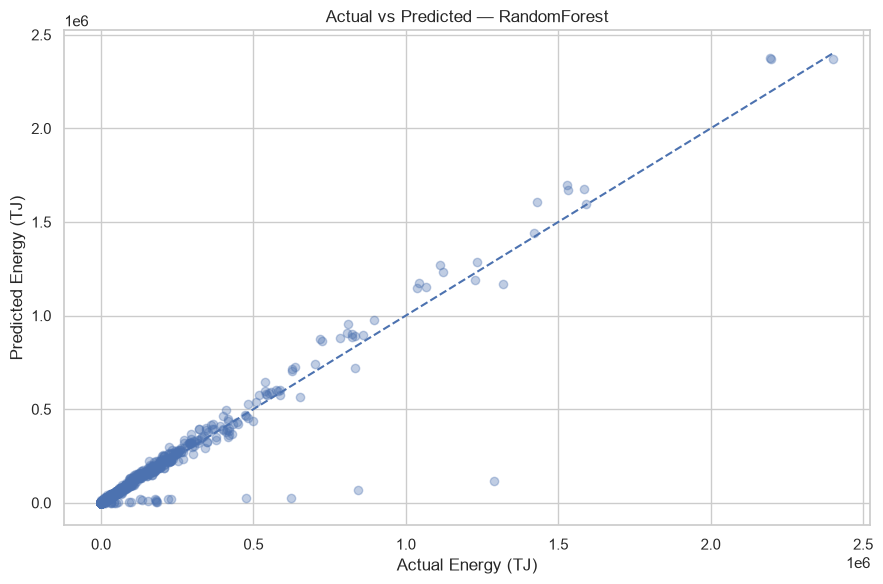

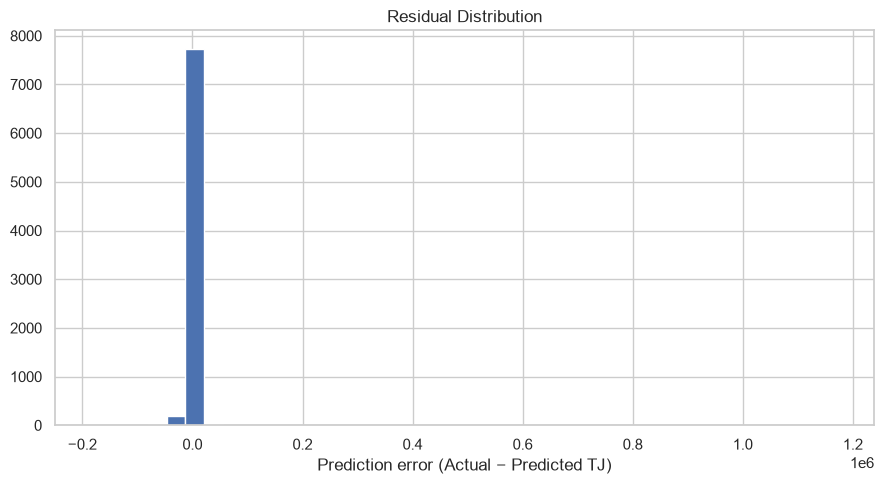

In [13]:
best_name = model_results.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]

plt.figure(figsize=(9, 6))
plt.scatter(y_test, best_pred, alpha=0.35)
lim_min = min(y_test.min(), best_pred.min())
lim_max = max(y_test.max(), best_pred.max())
plt.plot([lim_min, lim_max], [lim_min, lim_max], linestyle="--")
plt.xlabel("Actual Energy (TJ)")
plt.ylabel("Predicted Energy (TJ)")
plt.title(f"Actual vs Predicted — {best_name}")
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - best_pred
plt.figure(figsize=(9, 5))
plt.hist(residuals, bins=40)
plt.title("Residual Distribution")
plt.xlabel("Prediction error (Actual − Predicted TJ)")
plt.tight_layout()
plt.show()

## 8. Performance by country and series

In [14]:
test_results = test[["country","end_use_code","fuel_code","year",TARGET]].copy()
test_results["prediction"] = best_pred
test_results["residual"] = test_results[TARGET] - test_results["prediction"]
test_results["abs_error"] = test_results["residual"].abs()

country_metrics = test_results.groupby("country").apply(
    lambda x: pd.Series({
        "MAE": mean_absolute_error(x[TARGET], x["prediction"]),
        "RMSE": np.sqrt(mean_squared_error(x[TARGET], x["prediction"])),
        "records": len(x)
    }), include_groups=False
).sort_values("MAE")
display(country_metrics.head(15))
display(test_results.sort_values("abs_error", ascending=False).head(15))

,MAE,RMSE,records
country,,,
Malta,39.240,141.964,222.000
Montenegro,61.458,185.118,222.000
Cyprus,78.343,188.324,222.000
Luxembourg,104.915,314.760,222.000
Albania,174.856,421.577,222.000
North Macedonia,181.147,516.305,222.000
Latvia,208.084,616.045,222.000
Kosovo*,240.099,868.805,222.000
Estonia,258.036,805.555,222.000


,country,end_use_code,fuel_code,year,energy_tj,prediction,residual,abs_error
32063,Turkiye,FC_OTH_HH_E,TOTAL,2022,"1,287,738.246","116,939.821","1,170,798.425","1,170,798.425"
32201,Turkiye,FC_OTH_HH_E_SH,TOTAL,2022,"841,621.978","66,973.598","774,648.380","774,648.380"
32027,Turkiye,FC_OTH_HH_E,G3000,2022,"621,990.570","26,324.157","595,666.413","595,666.413"
32165,Turkiye,FC_OTH_HH_E_SH,G3000,2022,"474,747.780","23,843.138","450,904.642","450,904.642"
32051,Turkiye,FC_OTH_HH_E,RA000,2022,"228,115.020","21,960.049","206,154.971","206,154.971"
32024,Turkiye,FC_OTH_HH_E,E7000,2022,"220,273.960","19,880.437","200,393.523","200,393.523"
11753,Germany,FC_OTH_HH_E,TOTAL,2024,"2,194,688.254","2,376,427.896","-181,739.642","181,739.642"
32060,Turkiye,FC_OTH_HH_E,SFF_P1000_S2000,2022,"183,573.556","2,625.984","180,947.572","180,947.572"
32198,Turkiye,FC_OTH_HH_E_SH,SFF_P1000_S2000,2022,"181,535.215","2,037.889","179,497.326","179,497.326"
12442,Germany,FC_OTH_HH_E_SH,TOTAL,2023,"1,429,354.990","1,606,315.274","-176,960.284","176,960.284"


## 9. Final refit on all rows

In [15]:
# Refit the selected model on the full historical dataset for production predictions.
final_estimator = models[best_name]
final_pipeline = Pipeline([("preprocessor", preprocessor), ("model", final_estimator)])
final_pipeline.fit(df[FEATURES], df[TARGET])

print("Selected model:", best_name)

Selected model: RandomForest


## 10. Export prediction-ready artifact & feature metadata

In [16]:
bundle = {
    "model": final_pipeline,
    "model_name": best_name,
    "features": FEATURES,
    "categorical_features": CAT_FEATURES,
    "numeric_features": NUM_FEATURES,
    "series_keys": SERIES_KEYS,
    "target": TARGET,
    "min_year": int(df["year"].min()),
    "max_year": int(df["year"].max()),
    "country_options": sorted(df["country"].unique().tolist()),
    "end_use_options": sorted(df["end_use_code"].unique().tolist()),
    "fuel_options": sorted(df["fuel_code"].unique().tolist()),
    "training_median_lags": {
        "lag_1": float(df["lag_1"].median()),
        "lag_2": float(df["lag_2"].median()),
        "lag_3": float(df["lag_3"].median()),
        "rolling_mean_3": float(df["rolling_mean_3"].median()),
        "rolling_std_3": float(df["rolling_std_3"].median()),
    }
}
joblib.dump(bundle, ARTIFACT_DIR / "energy_prediction_model.joblib")
model_results.to_csv(ARTIFACT_DIR / "model_comparison.csv", index=False)
test_results.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)
country_metrics.to_csv(ARTIFACT_DIR / "country_test_metrics.csv")
print("Saved:")
for p in ARTIFACT_DIR.glob("*"):
    print("-", p.resolve())

Saved:
- C:\Users\LOQ\Downloads\artifacts\country_test_metrics.csv
- C:\Users\LOQ\Downloads\artifacts\energy_prediction_model.joblib
- C:\Users\LOQ\Downloads\artifacts\model_comparison.csv
- C:\Users\LOQ\Downloads\artifacts\test_predictions.csv


## 11. Interactive prediction example

In [17]:
# Example prediction with a real series from the dataset.
example = df.iloc[-1].copy()
example_input = df.loc[[df.index[-1]], FEATURES].copy()
example_prediction = final_pipeline.predict(example_input)[0]
print("Actual:", float(example[TARGET]))
print("Prediction:", float(example_prediction), "TJ")
display(example_input)

Actual: 280723.415
Prediction: 283137.74355990544 TJ


,country,end_use_code,fuel_code,year,year_index,year_sq,lag_1,lag_2,lag_3,rolling_mean_3,rolling_std_3
33355,United Kingdom,FC_OTH_HH_E_WH,TOTAL,2019,9,81,"282,649.565","264,390.257","287,486.566","278,175.463","12,180.848"


## 12. Streamlit integration contract

The exported `artifacts/energy_prediction_model.joblib` bundle is intended to be loaded by your Streamlit app.

The prediction form should collect:
- **Country** — from `country_options`
- **End-use code** — from `end_use_options`
- **Fuel code** — from `fuel_options`
- **Year** — integer
- **Lag 1, Lag 2, Lag 3** — previous annual consumption values for that exact country/end-use/fuel series (TJ)

The model bundle includes the preprocessing pipeline, so the app should pass a DataFrame containing all feature columns with the exact names shown below. The scaler and one-hot encoder are already inside the fitted pipeline.

**Avoid using global median lag values for real forecasts** whenever the user's selected series has historical observations; retrieve that series' past values from the source CSV and calculate lag features. If no prior observations exist, label the prediction as an estimate with limited historical context.

In [18]:
# Ready-to-copy inference helper for your app:
def predict_energy(bundle, country, end_use_code, fuel_code, year,
                   lag_1, lag_2=np.nan, lag_3=np.nan,
                   rolling_mean_3=np.nan, rolling_std_3=np.nan):
    year_index = int(year) - bundle["min_year"]
    row = pd.DataFrame([{
        "country": country,
        "end_use_code": end_use_code,
        "fuel_code": fuel_code,
        "year": int(year),
        "year_index": year_index,
        "year_sq": year_index ** 2,
        "lag_1": lag_1,
        "lag_2": lag_2,
        "lag_3": lag_3,
        "rolling_mean_3": rolling_mean_3,
        "rolling_std_3": rolling_std_3
    }])
    prediction = bundle["model"].predict(row[bundle["features"]])[0]
    return max(0.0, float(prediction))

# Sample using the observed row's lag features:
sample = df.iloc[-1]
sample_pred = predict_energy(
    bundle,
    sample["country"], sample["end_use_code"], sample["fuel_code"], sample["year"],
    sample["lag_1"], sample["lag_2"], sample["lag_3"],
    sample["rolling_mean_3"], sample["rolling_std_3"]
)
print(f"Sample predicted consumption: {sample_pred:,.2f} TJ")

Sample predicted consumption: 283,137.74 TJ


In [19]:

MODELS_DIR = PROJECT_DIR.parent / "models"
if not MODELS_DIR.exists():
    MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)


joblib.dump(bundle, MODELS_DIR / "advanced_prediction_bundle.joblib")

['c:\\Users\\LOQ\\Downloads\\models\\advanced_prediction_bundle.joblib']